# Exp22 — Translation (low ε) and word order (mid ε) in the patching framework, plus a label-free representation measure

Extends Exp21 to the planned tasks it left out. Same harness (answer-position patching at resid / attn write / mlp write, per layer).

**Translation (concept patching, as in Dumas et al.).** Prompt: 5-shot `English: word / <Language>:`; the decision is at the final `:`. Item = pair of English concepts (c, c'); candidates are their translations in language L; label y says which concept is being translated. Cross donor = same pair in another target language with the label flipped (the concept should transfer while the output language stays the recipient's). Floor donor = same language, a different demo set, label flipped. Reported exactly like Exp21: floor-corrected compat, valid only where the same-language transfer is large.

**Word order (adjective-noun, clause order, adposition).** Decision at the last shared token before the orders diverge; cand0 = adjective-first / verb-first / adposition-first continuation, cand1 = the other. The correct label is fixed by the language, so there is **no same-language label flip to build a floor from**. Instead the cross donor is a language whose canonical order is *opposite* (EN/DE/ZH/HI vs FR/ES/AR for adjectives; HI vs the rest for clause order and adposition). Reported: `frac_flip = mean transfer toward the donor's order / (2 x mean |clean margin|)`; 1.0 = the donor's order preference fully overwrites the recipient's. A same-label donor from a different item is the null (should move the margin ~0 or make it more confident). **This is not floor-corrected**, so read it as "is the order decision readable across languages", not as a ratio to within-language transfer.

**Representation, label-free.** Exp21's `R_probe`/`R_cos` were NaN for IOI and negation because the label (which of two changing candidates is correct) has no fixed direction. `R_retr` fixes that: after per-language centering, retrieve the aligned item in the anchor language by cosine nearest neighbour; chance-corrected top-1. It needs no label and runs on the states Exp21 already saved, so the last cell also recomputes it for the Exp21 results.

**Not here:** ZH classifier and AR numeral polarity have no counterpart language, so there is no cross-language donor. They remain behavioural high-epsilon endpoints (Exp20 preflight); a within-language localization is possible but says nothing about sharing.

Untested on a GPU (no torch in my sandbox); item construction and analysis were tested with a mock tokenizer and synthetic data. MUSE download worked for you in Exp20; keep `./muse_dicts/` in the same working directory.

In [1]:
import os
for v in ("HTTP_PROXY","HTTPS_PROXY","ALL_PROXY","http_proxy","https_proxy","all_proxy"):
    os.environ.pop(v, None)              # drop the broken proxy
os.environ["HF_HUB_OFFLINE"] = "1"       # use only cached/local files, no network calls

In [2]:
# CELL 1 — config + data (edit MODELS / GPU_ID only)
import os
GPU_ID = 2
os.environ.setdefault("CUDA_VISIBLE_DEVICES", str(GPU_ID))
import json, math, random, itertools, warnings, difflib, urllib.request
from pathlib import Path
import numpy as np
OUT, OUT21 = Path("exp22_results"), Path("exp21_results"); OUT.mkdir(exist_ok=True)
MUSE_DIR = Path("muse_dicts"); MUSE_URL = "https://dl.fbaipublicfiles.com/arrival/dictionaries/en-{l}.txt"

MODELS = {"bloom-1b7": "bigscience/bloom-1b7", "bloom-7b1": "bigscience/bloom-7b1"}
def prepend_bos(key): return "gemma" in key
N_BASES, N_DEMOS, LAYER_STRIDE, SEED = 12, 5, 2, 0
KINDS = ("resid", "attn", "mlp"); FLOOR_MIN_FRAC = 0.30
TR_LANGS = ["fr", "es", "de", "zh", "ar", "hi"]
ANCHOR_TR, ANCHOR_ALT_TR = "fr", "es"
NV_TR = 3
LANGNAME = {"fr": "French", "es": "Spanish", "de": "German", "zh": "Chinese", "ar": "Arabic", "hi": "Hindi"}
PRED_EPS = {"translation": 0, "word_order": 1}      # ordinal, from task structure, fixed before running

# ---- WORD ORDER sentences: (good, permuted)
ORDER_CLAUSE = {
 "en": [("The boy read the book.","The boy the book read."),("She bought a car.","She a car bought."),("The dog chased the cat.","The dog the cat chased."),("We saw the movie.","We the movie saw."),("The teacher opened the door.","The teacher the door opened."),("They built a house.","They a house built.")],
 "fr": [("Le garçon lit le livre.","Le garçon le livre lit."),("Elle achète une voiture.","Elle une voiture achète."),("Le chien poursuit le chat.","Le chien le chat poursuit."),("Nous voyons le film.","Nous le film voyons."),("Le professeur ouvre la porte.","Le professeur la porte ouvre."),("Ils construisent une maison.","Ils une maison construisent.")],
 "es": [("El niño lee el libro.","El niño el libro lee."),("Ella compra un coche.","Ella un coche compra."),("El perro persigue al gato.","El perro al gato persigue."),("Nosotros vemos la película.","Nosotros la película vemos."),("El profesor abre la puerta.","El profesor la puerta abre."),("Ellos construyen una casa.","Ellos una casa construyen.")],
 "de": [("Der Junge liest das Buch.","Der Junge das Buch liest."),("Sie kauft ein Auto.","Sie ein Auto kauft."),("Der Hund jagt die Katze.","Der Hund die Katze jagt."),("Wir sehen den Film.","Wir den Film sehen."),("Der Lehrer öffnet die Tür.","Der Lehrer die Tür öffnet."),("Sie bauen ein Haus.","Sie ein Haus bauen.")],
 "zh": [("男孩读那本书。","男孩那本书读。"),("她买一辆车。","她一辆车买。"),("狗追猫。","狗猫追。"),("我们看电影。","我们电影看。"),("老师打开门。","老师门打开。"),("他们盖房子。","他们房子盖。")],
 "hi": [("लड़के ने किताब पढ़ी।","लड़के ने पढ़ी किताब।"),("उसने गाड़ी खरीदी।","उसने खरीदी गाड़ी।"),("कुत्ते ने बिल्ली का पीछा किया।","कुत्ते ने किया बिल्ली का पीछा।"),("हमने फ़िल्म देखी।","हमने देखी फ़िल्म।"),("शिक्षक ने दरवाज़ा खोला।","शिक्षक ने खोला दरवाज़ा।"),("उन्होंने घर बनाया।","उन्होंने बनाया घर।")],
}
ORDER_ADP = {
 "en": [("The cat sleeps in the house.","The cat sleeps the house in."),("She walked to the school.","She walked the school to."),("He works with his father.","He works his father with."),("They live near the river.","They live the river near."),("The book is on the table.","The book is the table on."),("We arrived after the storm.","We arrived the storm after.")],
 "fr": [("Le chat dort dans la maison.","Le chat dort la maison dans."),("Elle est allée à l'école.","Elle est allée l'école à."),("Il travaille avec son père.","Il travaille son père avec."),("Ils habitent près de la rivière.","Ils habitent la rivière près de."),("Le livre est sur la table.","Le livre est la table sur."),("Nous sommes arrivés après la tempête.","Nous sommes arrivés la tempête après.")],
 "es": [("El gato duerme en la casa.","El gato duerme la casa en."),("Ella fue a la escuela.","Ella fue la escuela a."),("Él trabaja con su padre.","Él trabaja su padre con."),("Viven cerca del río.","Viven del río cerca."),("El libro está sobre la mesa.","El libro está la mesa sobre."),("Llegamos después de la tormenta.","Llegamos la tormenta después de.")],
 "de": [("Die Katze schläft im Haus.","Die Katze schläft Haus im."),("Sie ging zur Schule.","Sie ging Schule zur."),("Er arbeitet mit seinem Vater.","Er arbeitet seinem Vater mit."),("Sie wohnen am Fluss.","Sie wohnen Fluss am."),("Das Buch liegt auf dem Tisch.","Das Buch liegt dem Tisch auf."),("Wir sprachen über das Problem.","Wir sprachen das Problem über.")],
 "zh": [("猫在房子里睡觉。","猫房子里在睡觉。"),("书在桌子上。","书桌子上在。"),("他们住在河边。","他们住河边在。"),("孩子在学校里学习。","孩子学校里在学习。"),("她坐在车上。","她坐车上在。"),("他躺在床上。","他躺床上在。")],
 "ar": [("تنام القطة في البيت.","تنام القطة البيت في."),("ذهبت إلى المدرسة.","ذهبت المدرسة إلى."),("يعمل مع والده.","يعمل والده مع."),("يسكنون قرب النهر.","يسكنون النهر قرب."),("الكتاب على الطاولة.","الكتاب الطاولة على."),("وصلنا بعد العاصفة.","وصلنا العاصفة بعد.")],
 "hi": [("बिल्ली घर में सोती है।","बिल्ली में घर सोती है।"),("किताब मेज़ पर है।","किताब पर मेज़ है।"),("लड़का स्कूल में पढ़ता है।","लड़का में स्कूल पढ़ता है।"),("वे नदी के पास रहते हैं।","वे के पास नदी रहते हैं।"),("हम तूफ़ान के बाद पहुँचे।","हम बाद के तूफ़ान पहुँचे।"),("वह स्कूल तक गया।","वह तक स्कूल गया।")],
}
ADJ_PRE = {"en": True, "de": True, "zh": True, "hi": True, "fr": False, "es": False, "ar": False}
ADJ_CARRIER = {"en": ("She bought", "."), "fr": ("Elle a acheté", "."), "es": ("Ella compró", "."), "de": ("Sie kaufte", "."), "zh": ("她买了", "。"), "ar": ("اشترت", "."), "hi": ("उसने", " खरीदी।")}
ADJ_NP = {
 "en": [("a","red","car"),("a","green","book"),("a","black","hat"),("a","white","shirt"),("a","blue","bag"),("a","round","table")],
 "fr": [("une","rouge","voiture"),("un","vert","livre"),("un","noir","chapeau"),("une","blanche","chemise"),("un","bleu","sac"),("une","ronde","table")],
 "es": [("un","rojo","coche"),("un","verde","libro"),("un","negro","sombrero"),("una","blanca","camisa"),("un","azul","bolso"),("una","redonda","mesa")],
 "de": [("ein","rotes","Auto"),("ein","grünes","Buch"),("einen","schwarzen","Hut"),("ein","weißes","Hemd"),("eine","blaue","Tasche"),("einen","runden","Tisch")],
 "zh": [("一辆","红色的","车"),("一本","绿色的","书"),("一顶","黑色的","帽子"),("一件","白色的","衬衫"),("一个","蓝色的","包"),("一张","圆形的","桌子")],
 "ar": [("","حمراء","سيارة"),("","أخضر","كتابا"),("","سوداء","قبعة"),("","أبيض","قميصا"),("","زرقاء","حقيبة"),("","مستديرة","طاولة")],
 "hi": [("एक","लाल","गाड़ी"),("एक","हरी","किताब"),("एक","काली","टोपी"),("एक","सफ़ेद","कमीज़"),("एक","नीली","कुर्सी"),("एक","गोल","मेज़")],
}
WO_LANGS = {"adj": ["en","fr","es","de","zh","ar","hi"], "clause": ["en","fr","es","de","zh","hi"], "adp": ["en","fr","es","de","zh","ar","hi"]}
def wo_label(sub, lang):     # y = index of the grammatical continuation; cand0 = adj-first / verb-first / adposition-first
    if sub == "adj": return 0 if ADJ_PRE[lang] else 1
    return 1 if lang == "hi" else 0
def wo_donor(sub, lang):     # a language whose canonical order is opposite
    if sub == "adj": return "fr" if ADJ_PRE[lang] else "en"
    return "en" if lang == "hi" else "hi"
print("config ok")

config ok


In [3]:
# CELL 2 — helpers: tokenization, translation concepts, word-order items
def enc(tok, text): return tok(text, add_special_tokens=False)["input_ids"]
def new_tokens(tok, prefix, cont):
    a, b = enc(tok, prefix), enc(tok, prefix + cont)
    return b[len(a):] if b[:len(a)] == a else None

# ---------- translation
def load_muse(l):
    p = MUSE_DIR / f"en-{l}.txt"
    if not p.exists():
        try: MUSE_DIR.mkdir(exist_ok=True); urllib.request.urlretrieve(MUSE_URL.format(l=l), p)
        except Exception as e: print("MUSE download failed for", l, e); return None
    return [tuple(x.split()) for x in p.read_text(encoding="utf-8").splitlines() if len(x.split()) == 2]
def clean_pairs(l, pairs):
    ss, tt, out = set(), set(), []
    for s, t in pairs:
        if not (s.isascii() and s.isalpha() and s.islower() and len(s) >= 3): continue
        if s in ss or t in tt or t.casefold() == s: continue
        if l in ("fr", "es", "de") and (not t.isalpha() or difflib.SequenceMatcher(None, s, t.casefold()).ratio() >= 0.8): continue
        ss.add(s); tt.add(t); out.append((s, t))
    return out
def build_concepts():
    tr = {}
    for l in TR_LANGS:
        p = load_muse(l)
        if not p: return None
        tr[l] = dict(clean_pairs(l, p))
    common = sorted(set.intersection(*[set(d) for d in tr.values()])); random.Random(SEED).shuffle(common)
    return tr, common
_c = build_concepts()
if _c:
    TR, COMMON = _c; DEMO_C, TEST_C = COMMON[:40], COMMON[40:]
    TR_PAIRS = [tuple(random.Random(SEED + i).sample(TEST_C, 2)) for i in range(400)] if len(TEST_C) >= 20 else []
    print("shared concepts across", TR_LANGS, ":", len(COMMON), "| test pairs:", len(TR_PAIRS))
else: TR, COMMON, TR_PAIRS = None, [], []

def tr_render(lang, core, v, y):
    c, c2 = core; rng = random.Random(1000 + v); ds = rng.sample(DEMO_C, N_DEMOS)
    prefix = "".join(f"English: {w}\n{LANGNAME[lang]}: {TR[lang][w]}\n\n" for w in ds) + f"English: {c if y == 0 else c2}\n{LANGNAME[lang]}:"
    return prefix, TR[lang][c], TR[lang][c2], " "
def tr_valid(tok, lang, core, v):
    for y in (0, 1):
        pr, c0, c1, sep = tr_render(lang, core, v, y)
        if not (new_tokens(tok, pr, sep + c0) and new_tokens(tok, pr, sep + c1)): return False
    return True
def tr_items(tok, lang, donor):
    out = []
    for core in TR_PAIRS:
        v = len(out) % NV_TR; v2 = (v + 1) % NV_TR
        if all(tr_valid(tok, lg, core, vv) for lg, vv in ((lang, v), (lang, v2), (donor, v))): out.append((core, v))
        if len(out) >= N_BASES: break
    return [dict(core=c, variant=v, y=y) for c, v in out for y in (0, 1)]

# ---------- word order
def split_pair(lang, good, bad):
    cp = os.path.commonprefix([good, bad])
    if lang != "zh": cp = cp[:cp.rfind(" ")] if " " in cp else cp
    pre = cp.rstrip() if lang != "zh" else cp
    return pre, good[len(pre):], bad[len(pre):]
def wo_data(sub, lang):
    if sub == "clause": pairs = ORDER_CLAUSE[lang]
    elif sub == "adp": pairs = ORDER_ADP[lang]
    else:
        left, right = ADJ_CARRIER[lang]; join = "" if lang == "zh" else " "; pairs = []
        for art, adj, noun in ADJ_NP[lang]:
            pre = [x for x in (left, art, adj, noun) if x]; post = [x for x in (left, art, noun, adj) if x]
            g, b = (pre, post) if ADJ_PRE[lang] else (post, pre); pairs.append((join.join(g) + right, join.join(b) + right))
    out, y = [], wo_label(sub, lang)
    for g, b in pairs:
        pre, cg, cb = split_pair(lang, g, b); out.append((pre, cg, cb) if y == 0 else (pre, cb, cg))      # (prefix, cand0, cand1)
    return out
WO = {(s, l): wo_data(s, l) for s, ls in WO_LANGS.items() for l in ls}
def wo_valid(tok, sub, lang, idx):
    pr, c0, c1 = WO[(sub, lang)][idx]; return bool(pr and new_tokens(tok, pr, c0) and new_tokens(tok, pr, c1))
def wo_items(tok, lang):
    items = []
    for sub, ls in WO_LANGS.items():
        if lang not in ls: continue
        D, n = wo_donor(sub, lang), len(WO[(sub, lang)])
        for idx in range(n):
            if all(wo_valid(tok, sub, lg, ix) for lg, ix in ((lang, idx), (lang, (idx + 1) % n), (D, idx % len(WO[(sub, D)])))): items.append(dict(sub=sub, idx=idx, donor=D))
    return items
print("helpers ok; word-order cells:", len(WO))

shared concepts across ['fr', 'es', 'de', 'zh', 'ar', 'hi'] : 2523 | test pairs: 400
helpers ok; word-order cells: 20


In [4]:
# CELL 3 — numpy analysis
def compat_curves(Pc, Ps, m_clean, y, boots=300, seed=0):
    sgn = (1 - 2 * y)[:, None]
    Tc, Ts = (Pc - m_clean[:, None]) * sgn, (Ps - m_clean[:, None]) * sgn
    scale = np.abs(m_clean).mean(); tc, ts = Tc.mean(0), Ts.mean(0); valid = ts >= FLOOR_MIN_FRAC * scale
    with np.errstate(divide="ignore", invalid="ignore"): comp = np.where(valid, tc / ts, np.nan)
    rng, n, bs = np.random.default_rng(seed), len(y), []
    for _ in range(boots):
        ix = rng.integers(0, n, n); a, b, sc = Tc[ix].mean(0), Ts[ix].mean(0), np.abs(m_clean[ix]).mean()
        with np.errstate(divide="ignore", invalid="ignore"): bs.append(np.where(b >= FLOOR_MIN_FRAC * sc, a / b, np.nan))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore"); lo, hi = np.nanpercentile(np.array(bs), [2.5, 97.5], axis=0)
    return dict(compat=comp, lo=lo, hi=hi, valid=valid, Tc=tc, Ts=ts)

def order_transfer(Pc, Pn, m_clean, y, boots=300, seed=0):
    # Pc: patched margins with an opposite-order cross donor; Pn: with a same-label (null) donor from another item
    sgn = (1 - 2 * y)[:, None]; denom = 2 * np.abs(m_clean).mean()
    Tc, Tn = (Pc - m_clean[:, None]) * sgn, (Pn - m_clean[:, None]) * (-sgn)
    rng, n, bs = np.random.default_rng(seed), len(y), []
    for _ in range(boots):
        ix = rng.integers(0, n, n); bs.append(Tc[ix].mean(0) / (2 * np.abs(m_clean[ix]).mean()))
    lo, hi = np.percentile(np.array(bs), [2.5, 97.5], axis=0)
    return dict(frac_flip=Tc.mean(0) / denom, lo=lo, hi=hi, null=Tn.mean(0) / denom, flip_rate=((Pc * sgn) > 0).mean(0))

def retrieval(HA, HL):
    # label-free: does the anchor's aligned item sit nearest to this item after per-language centering?
    n, nl, rows = HL.shape[0], HL.shape[1], []
    for l in range(nl):
        A, B = HA[:, l] - HA[:, l].mean(0), HL[:, l] - HL[:, l].mean(0)
        A = A / (np.linalg.norm(A, axis=1, keepdims=True) + 1e-9); B = B / (np.linalg.norm(B, axis=1, keepdims=True) + 1e-9)
        S = B @ A.T; rank = (S > np.diag(S)[:, None]).sum(1) + 1; top1 = float((rank == 1).mean())
        rows.append(dict(layer=l, top1=top1, R_retr=(top1 - 1 / n) / (1 - 1 / n), mrr=float((1 / rank).mean())))
    return rows
print("analysis functions ok")

analysis functions ok


In [5]:
# CELL 4 — run (GPU): translation (generic floor-corrected design) and word order (opposite-order donors)
import torch, gc, time
from transformers import AutoTokenizer, AutoModelForCausalLM
dev = "cuda" if torch.cuda.is_available() else "cpu"

def get_modules(model):
    if hasattr(model, "transformer") and hasattr(model.transformer, "h"):
        bl = list(model.transformer.h)
        return dict(resid=bl, attn=[b.self_attention.dense for b in bl], mlp=[b.mlp.dense_4h_to_h for b in bl], ln_f=model.transformer.ln_f, lm_head=model.lm_head)
    bl = list(model.model.layers)
    return dict(resid=bl, attn=[b.self_attn.o_proj for b in bl], mlp=[b.mlp.down_proj for b in bl], ln_f=model.model.norm, lm_head=model.lm_head)
def patch_hook(p, vec):
    def hook(mod, inp, out):
        tup = isinstance(out, tuple); o = (out[0] if tup else out).clone(); o[:, p] = vec.to(o.dtype)
        return (o,) + tuple(out[1:]) if tup else o
    return hook
@torch.no_grad()
def margin(model, mods, tok, bos, prefix, c0t, c1t, patch=None):
    ids = bos + enc(tok, prefix); p = len(ids) - 1
    rows = [ids + c0t, ids + c1t]; T = max(map(len, rows)); pad = tok.pad_token_id if tok.pad_token_id is not None else 0
    inp = torch.tensor([r + [pad] * (T - len(r)) for r in rows], device=dev); att = torch.tensor([[1] * len(r) + [0] * (T - len(r)) for r in rows], device=dev)
    h = mods[patch[0]][patch[1]].register_forward_hook(patch_hook(p, patch[2])) if patch else None
    try: logits = model(input_ids=inp, attention_mask=att).logits
    finally:
        if h: h.remove()
    lp = []
    for r, ct in enumerate((c0t, c1t)):
        g = torch.log_softmax(logits[r, p:p + len(ct)].float(), -1); lp.append(sum(g[j, t].item() for j, t in enumerate(ct)))
    return lp[1] - lp[0]
@torch.no_grad()
def capture(model, mods, tok, bos, prefix):
    ids = bos + enc(tok, prefix); p = len(ids) - 1; nl = len(mods["resid"]); store = {k: [None] * nl for k in KINDS}; hs = []
    for k in KINDS:
        for li, m in enumerate(mods[k]):
            def hk(mod, inp, out, k=k, li=li):
                o = out[0] if isinstance(out, tuple) else out; store[k][li] = o[0, p].detach()
            hs.append(m.register_forward_hook(hk))
    try: model(input_ids=torch.tensor([ids], device=dev))
    finally:
        for h in hs: h.remove()
    return {k: torch.stack(v) for k, v in store.items()}

for key, path in MODELS.items():
    tok = AutoTokenizer.from_pretrained(path); bos = [tok.bos_token_id] if prepend_bos(key) else []
    model = AutoModelForCausalLM.from_pretrained(path, torch_dtype=torch.bfloat16).to(dev).eval()
    mods = get_modules(model); nl = len(mods["resid"]); LAYERS = sorted(set(list(range(0, nl, LAYER_STRIDE)) + [nl - 1])); H = mods["lm_head"].weight.shape[1]
    cache = {}
    def cap(prefix):
        if prefix not in cache: cache[prefix] = capture(model, mods, tok, bos, prefix)
        return cache[prefix]
    # ---- translation
    if TR:
        for L in TR_LANGS:
            f = OUT / f"{key}__translation__{L}.npz"
            if f.exists(): print("cached", f.name); continue
            D = ANCHOR_TR if L != ANCHOR_TR else ANCHOR_ALT_TR; items = tr_items(tok, L, D)
            if len(items) < 12: print("SKIP", key, L, len(items)); continue
            n, t0 = len(items), time.time(); y = np.array([it["y"] for it in items]); mc = np.zeros(n)
            P = {(d, k): np.zeros((n, len(LAYERS))) for d in ("cross", "same") for k in KINDS}
            HL = np.zeros((n, nl, H), dtype=np.float32); HA = np.zeros_like(HL)
            for i, it in enumerate(items):
                core, v, yy = it["core"], it["variant"], it["y"]; v2 = (v + 1) % NV_TR
                pr, c0, c1, sep = tr_render(L, core, v, yy); c0t, c1t = new_tokens(tok, pr, sep + c0), new_tokens(tok, pr, sep + c1)
                mc[i] = margin(model, mods, tok, bos, pr, c0t, c1t)
                dc, ds = cap(tr_render(D, core, v, 1 - yy)[0]), cap(tr_render(L, core, v2, 1 - yy)[0])
                for dn, dcap in (("cross", dc), ("same", ds)):
                    for k in KINDS:
                        for j, l in enumerate(LAYERS): P[(dn, k)][i, j] = margin(model, mods, tok, bos, pr, c0t, c1t, patch=(k, l, dcap[k][l]))
                HL[i] = cap(pr)["resid"].float().cpu().numpy(); HA[i] = cap(tr_render(D, core, v, yy)[0])["resid"].float().cpu().numpy()
            np.savez(f, y=y, m_clean=mc, layers=np.array(LAYERS), HL=HL, HA=HA, donor=np.array(D), **{f"P_{d}_{k}": P[(d, k)] for d in ("cross", "same") for k in KINDS})
            print(f"saved {f.name} n={n} clean acc={(((mc > 0).astype(int)) == y).mean():.2f} {time.time() - t0:.0f}s")
    # ---- word order
    for L in sorted({l for ls in WO_LANGS.values() for l in ls}):
        f = OUT / f"{key}__wordorder__{L}.npz"
        if f.exists(): print("cached", f.name); continue
        items = wo_items(tok, L)
        if len(items) < 6: print("SKIP", key, "word order", L, len(items)); continue
        n, t0 = len(items), time.time(); y = np.array([wo_label(it["sub"], L) for it in items]); mc = np.zeros(n)
        P = {(d, k): np.zeros((n, len(LAYERS))) for d in ("cross", "null") for k in KINDS}
        for i, it in enumerate(items):
            sub, idx, D = it["sub"], it["idx"], it["donor"]; ns = len(WO[(sub, L)])
            pr, c0, c1 = WO[(sub, L)][idx]; c0t, c1t = new_tokens(tok, pr, c0), new_tokens(tok, pr, c1)
            mc[i] = margin(model, mods, tok, bos, pr, c0t, c1t)
            dc, dn_ = cap(WO[(sub, D)][idx % len(WO[(sub, D)])][0]), cap(WO[(sub, L)][(idx + 1) % ns][0])
            for dn, dcap in (("cross", dc), ("null", dn_)):
                for k in KINDS:
                    for j, l in enumerate(LAYERS): P[(dn, k)][i, j] = margin(model, mods, tok, bos, pr, c0t, c1t, patch=(k, l, dcap[k][l]))
        np.savez(f, y=y, m_clean=mc, layers=np.array(LAYERS), sub=np.array([it["sub"] for it in items]), donor=np.array([it["donor"] for it in items]),
                 **{f"P_{d}_{k}": P[(d, k)] for d in ("cross", "null") for k in KINDS})
        print(f"saved {f.name} n={n} clean acc={(((mc > 0).astype(int)) == y).mean():.2f} {time.time() - t0:.0f}s")
    del model; gc.collect(); torch.cuda.empty_cache()

/home/anwoy/miniconda3/envs/ke/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
`torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 293/293 [00:00<00:00, 369.01it/s] 


saved bloom-1b7__translation__fr.npz n=24 clean acc=1.00 13s
saved bloom-1b7__translation__es.npz n=24 clean acc=1.00 13s
saved bloom-1b7__translation__de.npz n=24 clean acc=0.79 13s
saved bloom-1b7__translation__zh.npz n=24 clean acc=1.00 13s
saved bloom-1b7__translation__ar.npz n=24 clean acc=1.00 13s
saved bloom-1b7__translation__hi.npz n=24 clean acc=1.00 13s
saved bloom-1b7__wordorder__ar.npz n=12 clean acc=1.00 6s
saved bloom-1b7__wordorder__de.npz n=18 clean acc=0.83 10s
saved bloom-1b7__wordorder__en.npz n=18 clean acc=1.00 9s
saved bloom-1b7__wordorder__es.npz n=18 clean acc=1.00 9s
saved bloom-1b7__wordorder__fr.npz n=18 clean acc=1.00 9s
saved bloom-1b7__wordorder__hi.npz n=18 clean acc=0.94 10s
saved bloom-1b7__wordorder__zh.npz n=10 clean acc=1.00 6s


Loading weights: 100%|██████████| 365/365 [00:01<00:00, 292.54it/s]


saved bloom-7b1__translation__fr.npz n=24 clean acc=1.00 22s
saved bloom-7b1__translation__es.npz n=24 clean acc=1.00 21s
saved bloom-7b1__translation__de.npz n=24 clean acc=0.88 22s
saved bloom-7b1__translation__zh.npz n=24 clean acc=1.00 22s
saved bloom-7b1__translation__ar.npz n=24 clean acc=1.00 22s
saved bloom-7b1__translation__hi.npz n=24 clean acc=1.00 22s
saved bloom-7b1__wordorder__ar.npz n=12 clean acc=1.00 10s
saved bloom-7b1__wordorder__de.npz n=18 clean acc=0.94 15s
saved bloom-7b1__wordorder__en.npz n=18 clean acc=1.00 15s
saved bloom-7b1__wordorder__es.npz n=18 clean acc=1.00 15s
saved bloom-7b1__wordorder__fr.npz n=18 clean acc=1.00 15s
saved bloom-7b1__wordorder__hi.npz n=18 clean acc=1.00 15s
saved bloom-7b1__wordorder__zh.npz n=10 clean acc=1.00 8s


TRANSLATION
     model lang donor  n  clean_acc  C_resid  valid_resid  C_attn  valid_attn  C_mlp  valid_mlp  R_retr
bloom-1b7   ar    fr 24       1.00     0.86            5     NaN           0    NaN          0     1.0
bloom-1b7   de    fr 24       0.79     1.13            5     NaN           0    NaN          0     1.0
bloom-1b7   es    fr 24       1.00     0.89            5    0.93           1    NaN          0     1.0
bloom-1b7   fr    es 24       1.00     0.92            5    1.17           1    NaN          0     1.0
bloom-1b7   hi    fr 24       1.00     0.84            5     NaN           0    NaN          0     1.0
bloom-1b7   zh    fr 24       1.00     0.79            4     NaN           0    NaN          0     1.0
bloom-7b1   ar    fr 24       1.00     0.80            7     NaN           0    NaN          0     1.0
bloom-7b1   de    fr 24       0.88     0.87            7     NaN           0    NaN          0     1.0
bloom-7b1   es    fr 24       1.00     0.83            7    

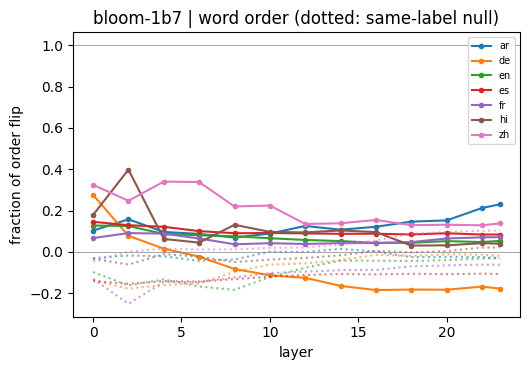

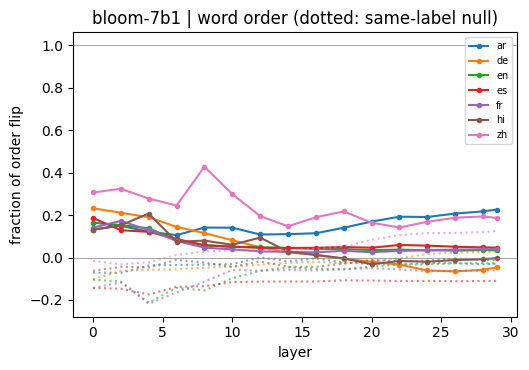

In [6]:
# CELL 5 — analysis (no GPU): translation compat + R_retr, word-order transfer, and R_retr for the saved Exp21 results
import pandas as pd
rows_t, rows_w, rows_r = [], [], []
for f in sorted(OUT.glob("*__translation__*.npz")):
    key, _, L = f.stem.split("__"); z = np.load(f); y, mc, layers = z["y"], z["m_clean"], z["layers"]
    rt = retrieval(z["HA"], z["HL"])
    for r in rt: r.update(model=key, task="translation", lang=L); rows_r.append(r)
    s = dict(model=key, task="translation", lang=L, donor=str(z["donor"]), n=len(y), clean_acc=round(float(((mc > 0).astype(int) == y).mean()), 2))
    for k in KINDS:
        cc = compat_curves(z[f"P_cross_{k}"], z[f"P_same_{k}"], mc, y)
        for j, l in enumerate(layers): rows_t.append(dict(model=key, lang=L, kind=k, layer=int(l), compat=cc["compat"][j], lo=cc["lo"][j], hi=cc["hi"][j], valid=bool(cc["valid"][j])))
        s[f"C_{k}"] = round(float(np.nanmedian(cc["compat"])), 2) if np.isfinite(cc["compat"]).any() else np.nan; s[f"valid_{k}"] = int(cc["valid"].sum())
    s["R_retr"] = round(float(pd.DataFrame(rt).R_retr.median()), 2); rows_t.append(dict(model=key, lang=L, kind="summary", **{c: v for c, v in s.items() if c not in ("model", "lang")}))
df_t = pd.DataFrame([r for r in rows_t if r["kind"] == "summary"])
if len(df_t): print("TRANSLATION\n", df_t[["model","lang","donor","n","clean_acc","C_resid","valid_resid","C_attn","valid_attn","C_mlp","valid_mlp","R_retr"]].to_string(index=False))
for f in sorted(OUT.glob("*__wordorder__*.npz")):
    key, _, L = f.stem.split("__"); z = np.load(f); y, mc, layers, subs = z["y"], z["m_clean"], z["layers"], z["sub"]
    for grp, mask in [("pooled", np.ones(len(y), bool))] + [(s_, subs == s_) for s_ in np.unique(subs)]:
        if mask.sum() < 3: continue
        for k in KINDS:
            ot = order_transfer(z[f"P_cross_{k}"][mask], z[f"P_null_{k}"][mask], mc[mask], y[mask])
            for j, l in enumerate(layers): rows_w.append(dict(model=key, lang=L, group=grp, kind=k, layer=int(l), n=int(mask.sum()), frac_flip=ot["frac_flip"][j], lo=ot["lo"][j], hi=ot["hi"][j], null=ot["null"][j], flip_rate=ot["flip_rate"][j]))
df_w = pd.DataFrame(rows_w)
if len(df_w):
    sw = df_w[(df_w.group == "pooled") & (df_w.kind == "resid")]
    late = sw[sw.layer >= sw.layer.max() * 0.5].groupby(["model", "lang"]).agg(n=("n", "first"), frac_flip_late_median=("frac_flip", "median"), frac_flip_max=("frac_flip", "max"), null_late_median=("null", "median")).round(2)
    print("\nWORD ORDER (resid, pooled over adjective / clause / adposition; fraction of a full order flip)\n", late.to_string())
    print("\nper sub-phenomenon, late-layer median:\n", df_w[(df_w.kind == "resid") & (df_w.group != "pooled") & (df_w.layer >= df_w.layer.max() * 0.5)].groupby(["model", "group", "lang"]).frac_flip.median().round(2).unstack("lang").to_string())
# R_retr for the Exp21 results (their saved HL/HA are aligned item-by-item)
for f in sorted(OUT21.glob("*.npz")) if OUT21.exists() else []:
    key, task, L = f.stem.split("__"); z = np.load(f); rt = retrieval(z["HA"], z["HL"])
    rows_r.append(dict(model=key, task=task, lang=L, layer=-1, top1=float(np.median([r["top1"] for r in rt])), R_retr=float(np.median([r["R_retr"] for r in rt])), mrr=float(np.median([r["mrr"] for r in rt]))))
df_r = pd.DataFrame([r for r in rows_r if r["layer"] == -1])
if len(df_r): print("\nR_retr (median over layers) for the Exp21 tasks, no labels needed:\n", df_r.round(2).sort_values(["model", "task", "lang"]).to_string(index=False))
pd.DataFrame(rows_t).to_csv(OUT / "translation_per_layer.csv", index=False); df_w.to_csv(OUT / "wordorder_per_layer.csv", index=False)
import matplotlib.pyplot as plt
for key in sorted({r["model"] for r in rows_w}):
    w = df_w[(df_w.model == key) & (df_w.group == "pooled") & (df_w.kind == "resid")]; fig, ax = plt.subplots(figsize=(5.4, 3.8))
    for L in w.lang.unique():
        a = w[w.lang == L]; ln, = ax.plot(a.layer, a.frac_flip, "-o", ms=3, label=L); ax.plot(a.layer, a.null, ":", color=ln.get_color(), alpha=.6)
    ax.axhline(0, color="gray", lw=.5); ax.axhline(1, color="gray", lw=.5); ax.set_title(f"{key} | word order (dotted: same-label null)"); ax.set_xlabel("layer"); ax.set_ylabel("fraction of order flip"); ax.legend(fontsize=7)
    plt.tight_layout(); plt.savefig(OUT / f"wordorder_{key}.png", dpi=140); plt.show()